In [ ]:
# Mukhammadsaiid Norbaev
# Data Visualisation 
# Coursework 

In [ ]:
# inspection

import pandas as pd
import matplotlib.pyplot as plt


# Load the dataset
df = pd.read_csv("UK-HPI-full-file-2025-10.csv")


# Check the rows
print("First 5 rows:")
print(df.head())


# Check the size of the dataset
print("\nDataset shape:")
print(df.shape)


# Show all column names
print("\nColumn names:")
print(df.columns.tolist())


# Check data types and missing values
print("\nDataset information:")
df.info()


# summary of the numerical columns
print("\nSummary statistics:")
print(df.describe())


# check how many missing values each column has
print("\nMissing values:")
print(df.isnull().sum())


# check for duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

First 5 rows:
         Date     RegionName   AreaCode  AveragePrice  Index  IndexSA  \
0  01/01/2004  Aberdeenshire  S12000034         84638   41.1      NaN   
1  01/02/2004  Aberdeenshire  S12000034         84623   41.1      NaN   
2  01/03/2004  Aberdeenshire  S12000034         86536   42.1      NaN   
3  01/04/2004  Aberdeenshire  S12000034         87373   42.5      NaN   
4  01/05/2004  Aberdeenshire  S12000034         89493   43.5      NaN   

   1m%Change  12m%Change  AveragePriceSA  SalesVolume  ...  NewPrice  \
0        NaN         NaN             NaN        388.0  ...  112843.0   
1        0.0         NaN             NaN        326.0  ...  113061.0   
2        2.3         NaN             NaN        453.0  ...  115218.0   
3        1.0         NaN             NaN        571.0  ...  115247.0   
4        2.4         NaN             NaN        502.0  ...  117377.0   

   NewIndex  New1m%Change  New12m%Change  NewSalesVolume  OldPrice  OldIndex  \
0      40.7           NaN         

In [7]:
# Data preparation


# Make a copy so the original data stays unchanged
clean_df = df.copy()


# Convert the Date column from text into a proper date
clean_df["Date"] = pd.to_datetime(
    clean_df["Date"],
    dayfirst=True
)


# Sort the dataset by date
clean_df = clean_df.sort_values("Date")


# Create a Year column
# This will make yearly analysis easier later
clean_df["Year"] = clean_df["Date"].dt.year


# Check the date range
print("\nDate range:")
print("First date:", clean_df["Date"].min())
print("Last date:", clean_df["Date"].max())


# Check the number of regions
print("\nNumber of regions:")
print(clean_df["RegionName"].nunique())


# Show some region names
print("\nExample regions:")
print(clean_df["RegionName"].unique()[:20])


# Check duplicates again
print("\nDuplicate rows:")
print(clean_df.duplicated().sum())



# Columns that may be useful for the analysis
main_columns = [
    "AveragePrice",
    "SalesVolume",
    "DetachedPrice",
    "SemiDetachedPrice",
    "TerracedPrice",
    "FlatPrice",
    "NewPrice",
    "OldPrice"
]


print("\nMissing values in main columns:")

for column in main_columns:
    print(column, ":", clean_df[column].isnull().sum())


Date range:
First date: 1968-04-01 00:00:00
Last date: 2025-10-01 00:00:00

Number of regions:
405

Example regions:
<StringArray>
[                   'Wales', 'Yorkshire and The Humber',
     'West Midlands Region',                   'London',
               'South West',                 'Scotland',
         'Northern Ireland',           'United Kingdom',
            'East Midlands',                  'England',
          'East of England',               'South East',
               'North East',            'Wolverhampton',
   'Windsor and Maidenhead',                'Bassetlaw',
                   'Wirral',               'Uttlesford',
    'Basingstoke and Deane',                   'Woking']
Length: 20, dtype: str

Duplicate rows:
0

Missing values in main columns:
AveragePrice : 0
SalesVolume : 4467
DetachedPrice : 6777
SemiDetachedPrice : 6777
TerracedPrice : 6666
FlatPrice : 6407
NewPrice : 7399
OldPrice : 7195


In [14]:
# # Columns that may be useful for the analysis
# main_columns = [
#     "AveragePrice",
#     "SalesVolume",
#     "DetachedPrice",
#     "SemiDetachedPrice",
#     "TerracedPrice",
#     "FlatPrice",
#     "NewPrice",
#     "OldPrice"
# ]


# print("\nMissing values in main columns:")

# for column in main_columns:
#     print(column, ":", clean_df[column].isnull().sum())

In [15]:
# EDA


# Look at basic statistics for house prices
print("\nAverage Price Statistics:")
print(clean_df["AveragePrice"].describe())


Average Price Statistics:
count    1.482750e+05
mean     1.824279e+05
std      1.307772e+05
min      2.553000e+03
25%      1.001685e+05
50%      1.541720e+05
75%      2.292860e+05
max      1.656986e+06
Name: AveragePrice, dtype: float64


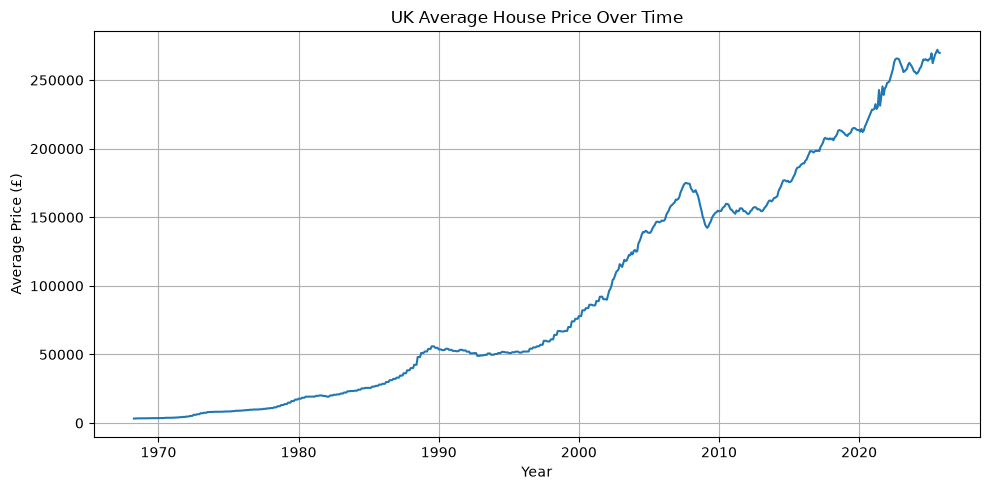

In [10]:
# Get only the United Kingdom rows
uk_data = clean_df[
    clean_df["RegionName"] == "United Kingdom"
]


# Plot UK average house prices over time
plt.figure(figsize=(10, 5))

plt.plot(
    uk_data["Date"],
    uk_data["AveragePrice"]
)

plt.title("UK Average House Price Over Time")
plt.xlabel("Year")
plt.ylabel("Average Price (£)")

plt.grid(True)
plt.tight_layout()

plt.show()

In [ ]:
# This graph shows a clear long-term increase in UK house prices from the late 1960s to 2025. 
# There are still noticeable periods where prices fall or stop growing, especially around 
# the early 1990s and the 2008 financial crisis. This made me interested in looking at how 
# different parts of the UK experienced these changes.

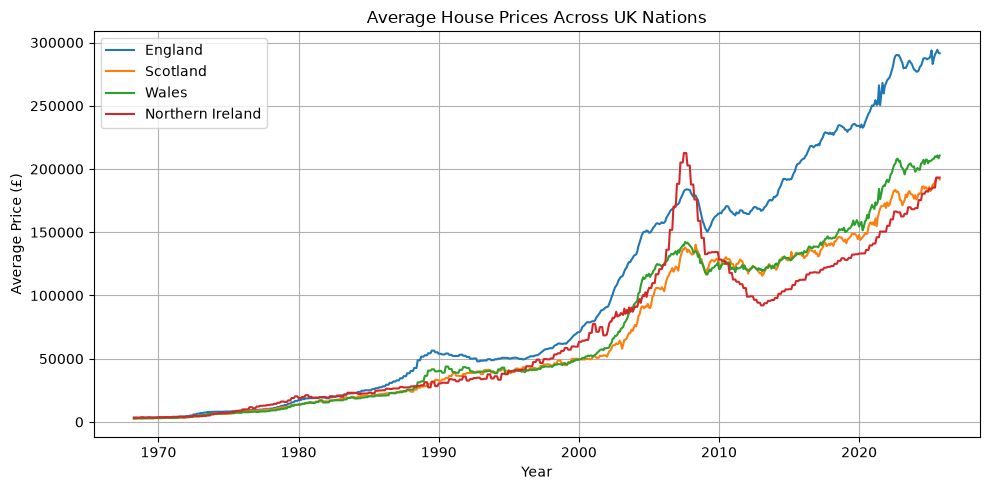

In [ ]:
# Get data for the four UK nations
england = clean_df[
    clean_df["RegionName"] == "England"
]

scotland = clean_df[
    clean_df["RegionName"] == "Scotland"
]

wales = clean_df[
    clean_df["RegionName"] == "Wales"
]

northern_ireland = clean_df[
    clean_df["RegionName"] == "Northern Ireland"
]


# Compare average prices over time
plt.figure(figsize=(10, 5))

plt.plot(
    england["Date"],
    england["AveragePrice"],
    label="England"
)

plt.plot(
    scotland["Date"],
    scotland["AveragePrice"],
    label="Scotland"
)

plt.plot(
    wales["Date"],
    wales["AveragePrice"],
    label="Wales"
)

plt.plot(
    northern_ireland["Date"],
    northern_ireland["AveragePrice"],
    label="Northern Ireland"
)

plt.title("Average House Prices Across UK Nations")
plt.xlabel("Year")
plt.ylabel("Average Price (£)")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [ ]:
# Here I compared England, Scotland, Wales and Northern Ireland. England is generally 
# the most expensive, but what stood out to me was Northern Ireland, where prices 
# increased very sharply before 2008 and then fell significantly. This is why 
# I thought comparing how the gap between the four nations changes over time 
# could be a useful research question.

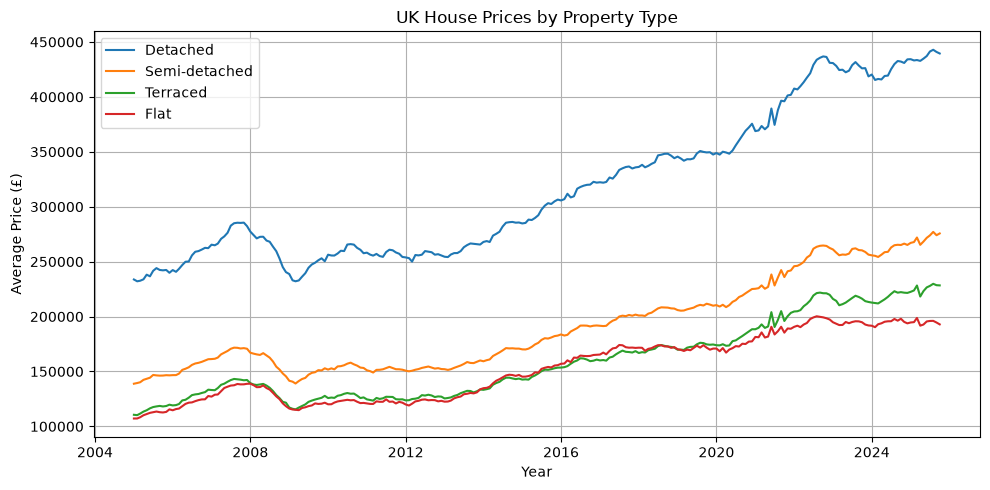

In [12]:
# Compare prices for different property types
plt.figure(figsize=(10, 5))

plt.plot(
    uk_data["Date"],
    uk_data["DetachedPrice"],
    label="Detached"
)

plt.plot(
    uk_data["Date"],
    uk_data["SemiDetachedPrice"],
    label="Semi-detached"
)

plt.plot(
    uk_data["Date"],
    uk_data["TerracedPrice"],
    label="Terraced"
)

plt.plot(
    uk_data["Date"],
    uk_data["FlatPrice"],
    label="Flat"
)

plt.title("UK House Prices by Property Type")
plt.xlabel("Year")
plt.ylabel("Average Price (£)")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [ ]:
# This graph compares detached, semi-detached, terraced houses and flats. 
# Detached properties are clearly the most expensive, and the difference 
# between detached homes and the other property types seems to become larger 
# over time. That made me want to look at whether different property 
# types have experienced different rates of price growth.

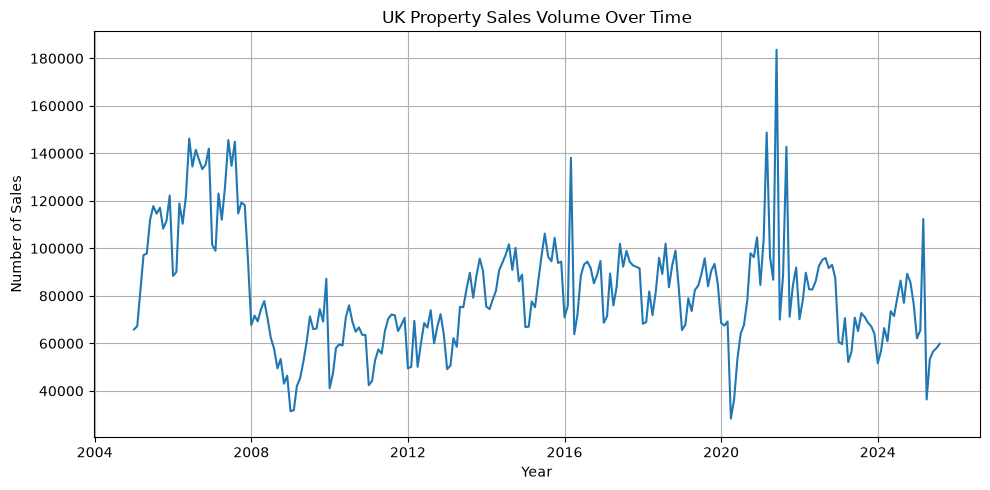

In [13]:
# Remove rows where UK sales volume is missing
uk_sales = uk_data.dropna(
    subset=["SalesVolume"]
)


# Plot UK sales volume over time
plt.figure(figsize=(10, 5))

plt.plot(
    uk_sales["Date"],
    uk_sales["SalesVolume"]
)

plt.title("UK Property Sales Volume Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Sales")

plt.grid(True)
plt.tight_layout()

plt.show()

In [ ]:
# Sales volume is much more unstable than house prices, with large rises and falls over time. 
# There are particularly noticeable changes around the financial crisis and around 2020–21. 
# I thought it would be interesting to investigate whether changes in the number of sales 
# are connected to changes in house prices.

In [ ]:
# Research questions

# How have average house prices evolved across the four UK nations and how has the gap between them changed over time?
# How have price differences between detached, semi-detached, terraced properties and flats changed in the UK since?
# How have changes in property sales volume corresponded with changes in UK house prices, especially during major market disruptions?
# before and after the pandemic (is recommended by the lecturer)